In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Preface
The fundamental building blocks of planet interior models are equations of state (EOS). In their most general sense, EOS are functional relationships between state variables -- in our case, pressure ($P$), volume ($V$) or density ($\rho$), and temperature ($T$). If you know the value of two of the variables then you can use the EOS to determine the third. In more mathy terms, EOS take the form of

$$\LARGE f(V, P, T) = 0$$

If you have taken in introductory physics course, you have almost certainly been exposed to an EOS; although, it may not have been referred to as an EOS. Any idea what EOS I'm referring to? If you're not sure, google equations of state and click on a couple sources. Most will mention this EOS early on as something along the lines of "the most widely known EOS".

The subsequent discussion on this notebook will be primarily framed in terms of solid materials as (1) solid materials form the building blocks of planets, (2) we can get better constraints on the material properties of solids relative to liquids/gases in general and especially at the pressures associated with planetary interiors, and (3) solids are the most intuitive (in my biased opinion).

# Common EOS for solid materials

The key question that needs to be addressed when deriving an EOS for solid materials is, how do they react to changes in their state, i.e., changes in $P$ and/or $V$ and/or $T$? 

All of the EOS we will discuss in this module assume the material in question is subject to *bulk*, or uniform/isostatic, compression. In other words, the pressure is the same in all directions / on all surfaces of the object. Further, we are going to assume that the compression of a material is isothermal, or its temperature does not change. In other words, we are discussing the isothermal uniform compression of solid materials. 

Pictorally, uniform compression looks something like:

![bulk_modulus_schematic.png](./figures/bulk_modulus_schematic.png)

Let's use this setup to start writing down some relationships between changes in pressure and volume. In particular, let's say we have an object sitting on our desk/table/etc with a measured volume $V_0$. At this point, we are not touching the object so the only pressure it is experiencing is atmospheric pressure (1 atm), which we'll call $P_0$. 

Next, we're going to squeeze the object (uniformly), increasing the applied pressure by some amount $\Delta P$. I want to know what the corresponding *fractional* change in the material's volume, or $\Delta V / V_0$. I could write something like

$$ \LARGE -\frac{\Delta V}{V_0} = \frac{\Delta P}{K_0} $$

where $K_0$ is some (yet) unknown constant of proportionality. A few questions to ponder with your classmates:

- What should the units of $K_0$ be? (i.e., should it have units of length, time, density, something else?)
- Why might I have included a minus sign in this equation?
- How can you interpret $K_0$ physically?

## ---------------------------------------Spoilers below--------------------------------------------

So, $K_0$ is probably the most fundamental parameter in EOS for solid materials. Therefore it gets a name! It is something called the bulk modulus and it is a measure of a materials resistance to *bulk*, or uniform/isostatic, compression. $K_0$ is sometimes referred to as the incompressibility of a material. If we do some rearranging of the expression and take the limit that $\Delta V \to 0$ (i.e., volume changes are infinitesimal), we can write out the standard definition of $K_0$,

$$ \LARGE K_0 \equiv -V_0\frac{dP}{dV} = \rho\frac{dP}{d\rho_0}$$


Here the subscipt 0 is to denote $K_0$, $V_0$, and $\rho_0$ are for some reference state prior to compression. In the scenario above, the reference state is just the uncompressed block at the ambient atmospheric pressure $P_0 = 1\mathrm{atm}$, which is *usually* the case. The pressures in planetary interiors are $\gg$ 1 atm and you will usually see 1 atm set equal to zero, or $P_0 = 0$. This is the standard, but you should still be cautious if you find yourself digging into the mineral physics literature, as sometimes it is more convienent to use a different reference state.




To this end, people can and do make many different assumptions and approximations. As such, there are many, many different EOS for solid materials scattered throughout the literature. We can't possible cover them all, so we limit ourselves to the two most common EOS used in planet interior models to describe solids: the ``third-order'' **Birch-Murnaghan** (BM3) and **Vinet** EOS. I'm not going to fully derive these here because it's not straightforward, it's tedious, it'll probably give you a headache, and it will take too long. As such, I will punt derivations to [Schulze, Hinkel+ 2026](https://ui.adsabs.harvard.edu/abs/2026PSJ.....7...30S/abstract) (Sect. 3) which is somewhat more approachable than most (I hope), or to [Introduction to the Physics of Earth's Interior](https://www.perplex.ethz.ch/thermo_course/various_thermodynamics_texts/Poirier%20-%20Introduction%20to%20the.pdf) by Jean-Paul Poirier for all the nitty gritty details.



which 

Take a look at the image below and try to come up with a more plain language summary of $K$. To start, I often find it useful to think of non-infinitesimal changes in $P$ and $V$ and 





The two most common EOS used in planet interior models to describe solids are called the ``third-order'' Birch-Murnaghan (BM3) and Vinet EOS. 

Both start from the following thermodynamic relationship:

$$\LARGE P = -\left(\frac{\partial F}{\partial V}\right)_T$$

where $F$ is the Helmholtz free energy. 



In [2]:
perov

NameError: name 'perov' is not defined

In [2]:
def simpEOS(rho, rho0, K0):
    return K0*np.log(rho/rho0)

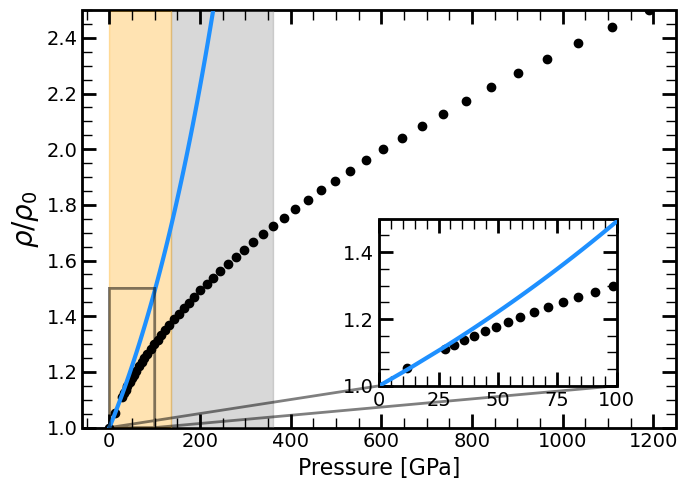

In [3]:
from matplotlib.ticker import MultipleLocator
fig, ax = plt.subplots(1,1, figsize = (7,5))
perov = pd.read_csv('Sakai_etal_2016_Table_S5_300K_data.csv')

K0 = 250

ax.plot(perov['P_GPa'], perov['rho/rho0'], 'ko')
ax.plot(simpEOS(perov['rho/rho0'], 1.0 , K0 ), perov['rho/rho0'], '-', color = 'dodgerblue', lw = 3)
#plt.xlim(0, 100)
ax.set_ylim(1, 2.5)
ax.fill_between([135, 360], [3,3], [0,0], color = 'gray', alpha = 0.3)
ax.fill_between([0, 135], [3,3], [0,0], color = 'orange', alpha = 0.3)

left, bottom, width, height = [0.5, 0.1, 0.4, 0.4]
ax2 = ax.inset_axes([left, bottom, width, height], xlim = (0, 100), ylim = (1, 1.5))
ax2.plot(perov['P_GPa'], perov['rho/rho0'], 'ko')
ax2.plot(simpEOS(perov['rho/rho0'], 1.0 , K0), perov['rho/rho0'], '-', color = 'dodgerblue', lw = 3)


ax.yaxis.set_major_locator(MultipleLocator(0.2))
ax.yaxis.set_minor_locator(MultipleLocator(0.05))

ax.xaxis.set_major_locator(MultipleLocator(200))
ax.xaxis.set_minor_locator(MultipleLocator(50))

ax.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14)
ax.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax.patch.set_edgecolor('black')  
ax.patch.set_linewidth(2) 


ax2.yaxis.set_major_locator(MultipleLocator(0.2))
ax2.yaxis.set_minor_locator(MultipleLocator(0.05))

ax2.xaxis.set_major_locator(MultipleLocator(25))
ax2.xaxis.set_minor_locator(MultipleLocator(5))

ax2.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14)
ax2.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax2.patch.set_edgecolor('black')  
ax2.patch.set_linewidth(2) 

#ax2.imshow(Z2, extent=extent, origin="lower")

ax.indicate_inset_zoom(ax2, edgecolor="black", lw = 2)

ax.set_xlabel('Pressure [GPa]', fontsize = 16)
ax.set_ylabel(r'$\rho / \rho_0$', fontsize = 20)


plt.tight_layout()
plt.savefig('simple_EOS.png', dpi = 300)

#plt.xscale('log')
#plt.yscale('log')

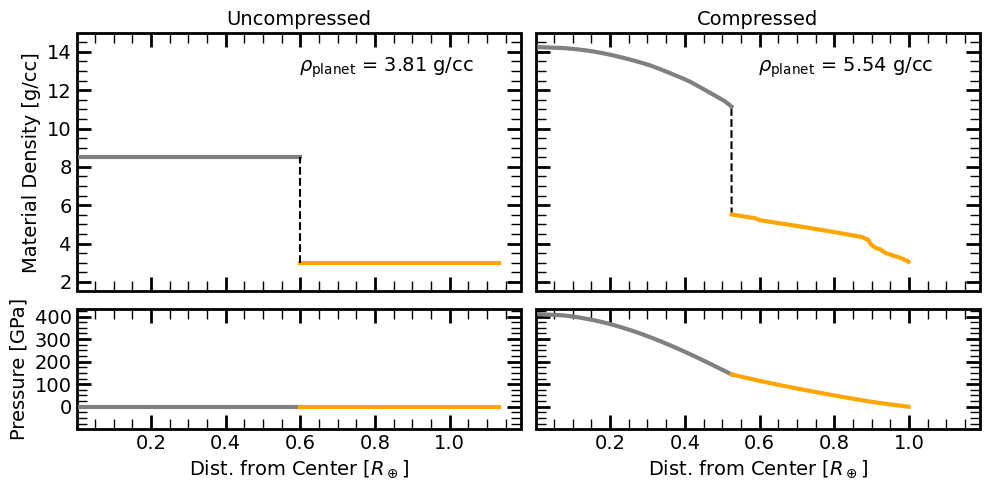

In [4]:
figure = plt.figure(figsize=(10, 5))
elike = pd.read_csv('exoplex_elike_1me.csv')
mpl = max(elike['Mass_Me']) # Earth masses

from matplotlib.ticker import MultipleLocator


rho_Fe = 8500.0
me = 5.972*(10**24)
cmf = 0.33
rho_sil = 3000.0
rcore = (((cmf*mpl*me)/rho_Fe)*(3.0/(4.0*np.pi)))**(1.0/3.0)
rpl = (((1.0-cmf)*mpl*me/rho_sil)*(3.0/(4.0*np.pi)) + (rcore**3))**(1.0/3.0)

rcore = rcore/6371000.0
rpl = rpl/6371000.0

ax1 = plt.subplot2grid((3, 4), (0, 0), colspan=2, rowspan=2)
ax2 = plt.subplot2grid((3, 4), (2, 0), colspan=2, rowspan=1)
ax3 = plt.subplot2grid((3, 4), (0, 2), colspan=2, rowspan=2)
ax4 = plt.subplot2grid((3, 4), (2, 2), colspan=2, rowspan=1)

ax1.set_title('Uncompressed', fontsize = 14)
ax3.set_title('Compressed', fontsize = 14)

ax1.plot([0.0, rcore], [8.5, 8.5], color = 'gray', lw = 3)
ax1.plot([rcore, rpl], [3.0, 3.0], color = 'orange', lw = 3)
ax1.plot([rcore, rcore], [rho_sil/1000.0, rho_Fe/1000.0], '--', color = 'k')
ax1.set_ylim(0.5*min(elike['Density_g_cc']), 1.05*max(elike['Density_g_cc']))
ax1.set_xlim(0.001, 1.19)

rho_un = round(5.512*(mpl/(rpl**3)),2)

ax1.annotate(r'$\rho_\mathrm{planet}$' + f' = {rho_un} g/cc', (0.5, 0.85), fontsize = 14, xycoords = 'axes fraction')

ax1.yaxis.set_major_locator(MultipleLocator(2))
ax1.yaxis.set_minor_locator(MultipleLocator(0.5))

ax1.xaxis.set_major_locator(MultipleLocator(0.2))
ax1.xaxis.set_minor_locator(MultipleLocator(0.05))

ax1.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14, labelbottom = False)
ax1.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax1.patch.set_edgecolor('black')  
ax1.patch.set_linewidth(2) 


ax2.plot([0.0, rcore], [0, 0], color = 'gray', lw = 3)
ax2.plot([rcore, rpl], [0, 0], color = 'orange', lw = 3)
ax2.set_ylim(-99, 1.05*max(elike['Pressure_GPa']))
ax2.set_xlim(0.001, 1.19)

ax2.yaxis.set_major_locator(MultipleLocator(100))
ax2.yaxis.set_minor_locator(MultipleLocator(25))

ax2.xaxis.set_major_locator(MultipleLocator(0.2))
ax2.xaxis.set_minor_locator(MultipleLocator(0.05))

ax2.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14)
ax2.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax2.patch.set_edgecolor('black')  
ax2.patch.set_linewidth(2) 




ind_core = np.where(elike['Fe'] == 100)
ind_mant = np.where(elike['Fe'] == 0)

ax3.plot(elike['Radius_km']/6371.0, elike['Density_g_cc'], color = 'k', ls = '--')
ax3.plot(elike['Radius_km'].iloc[ind_core]/6371.0, elike['Density_g_cc'].iloc[ind_core], color = 'gray', lw = 3)
ax3.plot(elike['Radius_km'].iloc[ind_mant]/6371.0, elike['Density_g_cc'].iloc[ind_mant], color = 'orange', lw = 3)
ax3.set_xlim(0.001, 1.19)


ax3.set_ylim(0.5*min(elike['Density_g_cc']), 1.05*max(elike['Density_g_cc']))

rpl = max(elike['Radius_km']/6371.0)
rho_cmp = round(5.512*(mpl/(rpl**3)),2)

ax3.annotate(r'$\rho_\mathrm{planet}$' + f' = {rho_cmp} g/cc', (0.5, 0.85), fontsize = 14, xycoords = 'axes fraction')

ax3.yaxis.set_major_locator(MultipleLocator(2))
ax3.yaxis.set_minor_locator(MultipleLocator(0.5))

ax3.xaxis.set_major_locator(MultipleLocator(0.2))
ax3.xaxis.set_minor_locator(MultipleLocator(0.05))

ax3.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14, labelbottom = False, labelleft = False)
ax3.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax3.patch.set_edgecolor('black')  
ax3.patch.set_linewidth(2) 

ax4.plot(elike['Radius_km'].iloc[ind_core]/6371.0, elike['Pressure_GPa'].iloc[ind_core], color = 'gray', lw = 3)
ax4.plot(elike['Radius_km'].iloc[ind_mant]/6371.0, elike['Pressure_GPa'].iloc[ind_mant], color = 'orange', lw = 3)
ax4.set_ylim(-99, 1.05*max(elike['Pressure_GPa']))
ax4.set_xlim(0.001, 1.19)

ax4.yaxis.set_major_locator(MultipleLocator(100))
ax4.yaxis.set_minor_locator(MultipleLocator(25))

ax4.xaxis.set_major_locator(MultipleLocator(0.2))
ax4.xaxis.set_minor_locator(MultipleLocator(0.05))

ax4.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14, labelleft = False)
ax4.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax4.patch.set_edgecolor('black')  
ax4.patch.set_linewidth(2) 


ax1.set_ylabel('Material Density [g/cc]', fontsize = 14)
ax2.set_ylabel('Pressure [GPa]', fontsize = 14)
ax2.set_xlabel(r'Dist. from Center [$R_\oplus$]', fontsize = 14)
ax4.set_xlabel(r'Dist. from Center [$R_\oplus$]', fontsize = 14)


plt.tight_layout()

plt.savefig('interior_profile_pltos.png', dpi = 300)


In [5]:
def BM3(rho, temperature, layer):
    x = (rho/layer.rho0)**(1.0/3.0)
    t1 = (3.0/2.0)*layer.K0*((x**7) - (x**5))
    t2 = 1.0 - (3.0/4.0)*(4.0 - layer.Kp0)*((x**2) - 1)
    return t1*t2



In [6]:
def vinet(rho, rho0, K0, Kp0):
    eta = rho0/rho
    t1 = 3.0*K0*(eta**(-2.0/3.0))
    t2 = 1.0-((eta**(1.0/3.0)))
    t3 = np.exp((3.0/2.0)*(Kp0-1.0)*t2)
    return t1*t2*t3

def bm3(rho, rho0, K0, Kp0):
    eta = rho/rho0
    t1 = (3.0/2.0)*K0*((eta**(7.0/3.0))-((eta**(5.0/3.0))))
    t2 = 1.0 + (3.0/4.0)*(Kp0-4.0)*((eta**(2.0/3.0))-1.0)
    return t1*t2

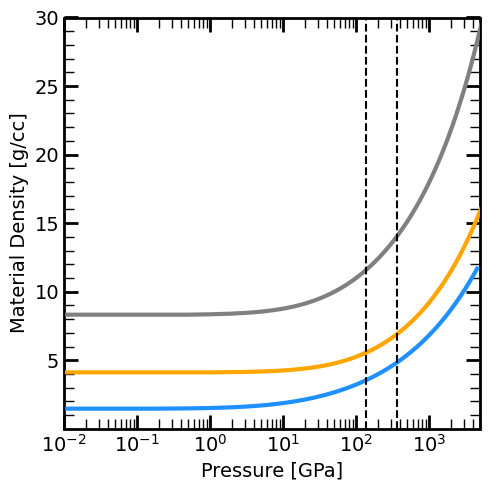

In [7]:
fig, ax = plt.subplots(1,1, figsize = (5,5))

rho0 = 8300.0
K0 = 156.2
Kp0 = 6.08
rho = np.linspace(rho0, 4*rho0, 1000)
ax.plot(vinet(rho, rho0, K0, Kp0), rho/1000, color = 'gray', lw = 3)


rho0 = 4100.0
K0 = 247.0
Kp0 = 3.97
rho = np.linspace(rho0, 5*rho0, 1000)
ax.plot(bm3(rho, rho0, K0, Kp0), rho/1000, color = 'orange', lw = 3)


rho0 = 1460.0
K0 = 23.7
Kp0 = 4.15
rho = np.linspace(rho0, 8*rho0, 1000)
ax.plot(bm3(rho, rho0, K0, Kp0), rho/1000, color = 'dodgerblue', lw = 3)


#ax.set_ylim(-99, 1.05*max(elike['Pressure_GPa']))
#ax.set_xlim(0.001, 1.19)

ax.yaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.set_minor_locator(MultipleLocator(1))


ax.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14)
ax.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax.patch.set_edgecolor('black')  
ax.patch.set_linewidth(2) 

ax.axvline(135, color = 'k', ls = '--')
ax.axvline(365, color = 'k', ls = '--')


ax.set_xscale('log')
ax.set_xlim(0.01, 5000)
ax.set_ylim(0.01, 30)

ax.set_ylabel('Material Density [g/cc]', fontsize = 14)
ax.set_xlabel('Pressure [GPa]', fontsize = 14)

plt.tight_layout()
plt.savefig('EOS_plot.png', dpi = 300)

#plt.yscale('log')

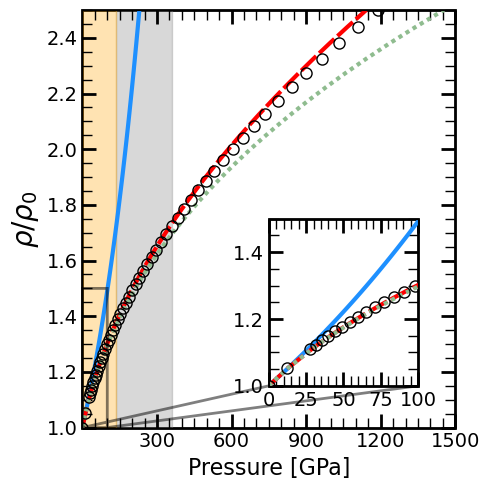

In [12]:
from matplotlib.ticker import MultipleLocator
fig, ax = plt.subplots(1,1, figsize = (5,5))
perov = pd.read_csv('Sakai_etal_2016_Table_S5_300K_data.csv')

K0 = 250

ax.plot(simpEOS(perov['rho/rho0'], 1.0 , K0 ), perov['rho/rho0'], '-', color = 'dodgerblue', lw = 3)
ax.plot(vinet(perov['rho/rho0'], 1.0, 222.0, 4.2), perov['rho/rho0'], color = 'red', lw = 3, ls = (0, (5, 1)))
ax.plot(bm3(perov['rho/rho0'], 1.0, 222.0, 4.2), perov['rho/rho0'], color = 'darkseagreen', lw = 3, ls = (0, (1, 1)))

ax.plot(perov['P_GPa'], perov['rho/rho0'], 'ko', fillstyle = 'none', markersize = 8)


#plt.xlim(0, 100)
ax.set_ylim(1, 2.5)
ax.fill_between([135, 360], [3,3], [0,0], color = 'gray', alpha = 0.3)
ax.fill_between([0, 135], [3,3], [0,0], color = 'orange', alpha = 0.3)

left, bottom, width, height = [0.5, 0.1, 0.4, 0.4]
ax2 = ax.inset_axes([left, bottom, width, height], xlim = (0, 100), ylim = (1, 1.5))
ax2.plot(simpEOS(perov['rho/rho0'], 1.0 , K0), perov['rho/rho0'], '-', color = 'dodgerblue', lw = 3)
ax2.plot(vinet(perov['rho/rho0'], 1.0, 222.0, 4.2), perov['rho/rho0'], color = 'red', lw = 3, ls = (0, (5, 1)))
ax2.plot(bm3(perov['rho/rho0'], 1.0, 222.0, 4.2), perov['rho/rho0'], color = 'darkseagreen', lw = 3, ls = (0, (1, 1)))
ax2.plot(perov['P_GPa'], perov['rho/rho0'], 'ko', fillstyle = 'none', markersize = 8)




ax.yaxis.set_major_locator(MultipleLocator(0.2))
ax.yaxis.set_minor_locator(MultipleLocator(0.05))

ax.xaxis.set_major_locator(MultipleLocator(300))
ax.xaxis.set_minor_locator(MultipleLocator(50))

ax.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14)
ax.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax.patch.set_edgecolor('black')  
ax.patch.set_linewidth(2) 


ax2.yaxis.set_major_locator(MultipleLocator(0.2))
ax2.yaxis.set_minor_locator(MultipleLocator(0.05))

ax2.xaxis.set_major_locator(MultipleLocator(25))
ax2.xaxis.set_minor_locator(MultipleLocator(5))

ax2.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14)
ax2.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax2.patch.set_edgecolor('black')  
ax2.patch.set_linewidth(2) 

#ax2.imshow(Z2, extent=extent, origin="lower")

ax.indicate_inset_zoom(ax2, edgecolor="black", lw = 2)

ax.set_xlabel('Pressure [GPa]', fontsize = 16)
ax.set_ylabel(r'$\rho / \rho_0$', fontsize = 20)


ax.set_xlim(0.001, 1500)

plt.tight_layout()
plt.savefig('vinet_BM3_simple_comparison_both.png', dpi = 300)

#plt.xscale('log')
#plt.yscale('log')

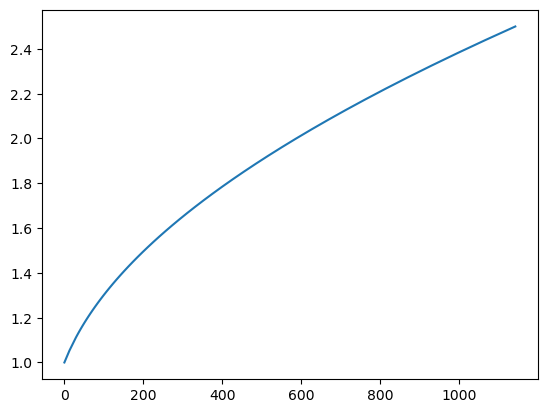

In [123]:
plt.plot(vinet(perov['rho/rho0'], 1.0, 222.0, 4.2), perov['rho/rho0'])


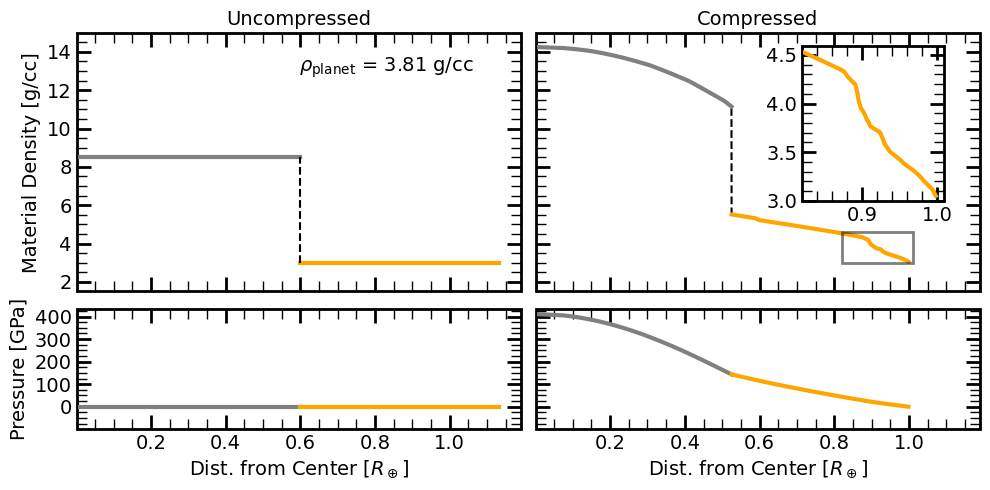

In [186]:
figure = plt.figure(figsize=(10, 5))
elike = pd.read_csv('exoplex_elike_1me.csv')
mpl = max(elike['Mass_Me']) # Earth masses

from matplotlib.ticker import MultipleLocator


rho_Fe = 8500.0
me = 5.972*(10**24)
cmf = 0.33
rho_sil = 3000.0
rcore = (((cmf*mpl*me)/rho_Fe)*(3.0/(4.0*np.pi)))**(1.0/3.0)
rpl = (((1.0-cmf)*mpl*me/rho_sil)*(3.0/(4.0*np.pi)) + (rcore**3))**(1.0/3.0)

rcore = rcore/6371000.0
rpl = rpl/6371000.0

ax1 = plt.subplot2grid((3, 4), (0, 0), colspan=2, rowspan=2)
ax2 = plt.subplot2grid((3, 4), (2, 0), colspan=2, rowspan=1)
ax3 = plt.subplot2grid((3, 4), (0, 2), colspan=2, rowspan=2)
ax4 = plt.subplot2grid((3, 4), (2, 2), colspan=2, rowspan=1)

ax1.set_title('Uncompressed', fontsize = 14)
ax3.set_title('Compressed', fontsize = 14)

ax1.plot([0.0, rcore], [8.5, 8.5], color = 'gray', lw = 3)
ax1.plot([rcore, rpl], [3.0, 3.0], color = 'orange', lw = 3)
ax1.plot([rcore, rcore], [rho_sil/1000.0, rho_Fe/1000.0], '--', color = 'k')
ax1.set_ylim(0.5*min(elike['Density_g_cc']), 1.05*max(elike['Density_g_cc']))
ax1.set_xlim(0.001, 1.19)

rho_un = round(5.512*(mpl/(rpl**3)),2)

ax1.annotate(r'$\rho_\mathrm{planet}$' + f' = {rho_un} g/cc', (0.5, 0.85), fontsize = 14, xycoords = 'axes fraction')

ax1.yaxis.set_major_locator(MultipleLocator(2))
ax1.yaxis.set_minor_locator(MultipleLocator(0.5))

ax1.xaxis.set_major_locator(MultipleLocator(0.2))
ax1.xaxis.set_minor_locator(MultipleLocator(0.05))

ax1.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14, labelbottom = False)
ax1.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax1.patch.set_edgecolor('black')  
ax1.patch.set_linewidth(2) 


ax2.plot([0.0, rcore], [0, 0], color = 'gray', lw = 3)
ax2.plot([rcore, rpl], [0, 0], color = 'orange', lw = 3)
ax2.set_ylim(-99, 1.05*max(elike['Pressure_GPa']))
ax2.set_xlim(0.001, 1.19)

ax2.yaxis.set_major_locator(MultipleLocator(100))
ax2.yaxis.set_minor_locator(MultipleLocator(25))

ax2.xaxis.set_major_locator(MultipleLocator(0.2))
ax2.xaxis.set_minor_locator(MultipleLocator(0.05))

ax2.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14)
ax2.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax2.patch.set_edgecolor('black')  
ax2.patch.set_linewidth(2) 


ind_core = np.where(elike['Fe'] == 100)
ind_mant = np.where(elike['Fe'] == 0)

ax3.plot(elike['Radius_km']/6371.0, elike['Density_g_cc'], color = 'k', ls = '--')
ax3.plot(elike['Radius_km'].iloc[ind_core]/6371.0, elike['Density_g_cc'].iloc[ind_core], color = 'gray', lw = 3)
ax3.plot(elike['Radius_km'].iloc[ind_mant]/6371.0, elike['Density_g_cc'].iloc[ind_mant], color = 'orange', lw = 3)
ax3.set_xlim(0.001, 1.19)


ax3.set_ylim(0.5*min(elike['Density_g_cc']), 1.05*max(elike['Density_g_cc']))

rpl = max(elike['Radius_km']/6371.0)
rho_cmp = round(5.512*(mpl/(rpl**3)),2)

#ax3.annotate(r'$\rho_\mathrm{planet}$' + f' = {rho_cmp} g/cc', (0.5, 0.85), fontsize = 14, xycoords = 'axes fraction')

ax3.yaxis.set_major_locator(MultipleLocator(2))
ax3.yaxis.set_minor_locator(MultipleLocator(0.5))

ax3.xaxis.set_major_locator(MultipleLocator(0.2))
ax3.xaxis.set_minor_locator(MultipleLocator(0.05))

ax3.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14, labelbottom = False, labelleft = False)
ax3.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax3.patch.set_edgecolor('black')  
ax3.patch.set_linewidth(2) 

ax4.plot(elike['Radius_km'].iloc[ind_core]/6371.0, elike['Pressure_GPa'].iloc[ind_core], color = 'gray', lw = 3)
ax4.plot(elike['Radius_km'].iloc[ind_mant]/6371.0, elike['Pressure_GPa'].iloc[ind_mant], color = 'orange', lw = 3)
ax4.set_ylim(-99, 1.05*max(elike['Pressure_GPa']))
ax4.set_xlim(0.001, 1.19)

ax4.yaxis.set_major_locator(MultipleLocator(100))
ax4.yaxis.set_minor_locator(MultipleLocator(25))

ax4.xaxis.set_major_locator(MultipleLocator(0.2))
ax4.xaxis.set_minor_locator(MultipleLocator(0.05))

ax4.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
                  labelsize = 14, labelleft = False)
ax4.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax4.patch.set_edgecolor('black')  
ax4.patch.set_linewidth(2) 


ax1.set_ylabel('Material Density [g/cc]', fontsize = 14)
ax2.set_ylabel('Pressure [GPa]', fontsize = 14)
ax2.set_xlabel(r'Dist. from Center [$R_\oplus$]', fontsize = 14)
ax4.set_xlabel(r'Dist. from Center [$R_\oplus$]', fontsize = 14)

left, bottom, width, height = [0.6, 0.35, 0.32, 0.6]
ax5 = ax3.inset_axes([left, bottom, width, height], xlim = (0.82, 1.01), ylim = (3, 4.59))
ax5.plot(elike['Radius_km'].iloc[ind_mant]/6371.0, elike['Density_g_cc'].iloc[ind_mant], color = 'orange', lw = 3)
#ax2.plot(vinet(perov['rho/rho0'], 1.0, 222.0, 4.2), perov['rho/rho0'], color = 'red', lw = 3, ls = (0, (5, 1)))
#ax2.plot(bm3(perov['rho/rho0'], 1.0, 222.0, 4.2), perov['rho/rho0'], color = 'darkseagreen', lw = 3, ls = (0, (1, 1)))


ax5.yaxis.set_major_locator(MultipleLocator(0.5))
ax5.yaxis.set_minor_locator(MultipleLocator(0.1))

ax5.xaxis.set_major_locator(MultipleLocator(0.1))
ax5.xaxis.set_minor_locator(MultipleLocator(0.02))

ax5.tick_params(which = 'major', direction = 'in', top = True, right = True, length = 10, width = 2, 
               labelsize = 14)
ax5.tick_params(which = 'minor', direction = 'in', top = True, right = True, length = 7.5, width = 1)

ax5.patch.set_edgecolor('black')  
ax5.patch.set_linewidth(2) 

#ax2.imshow(Z2, extent=extent, origin="lower")

ax3.indicate_inset_zoom(ax5, edgecolor="black", lw = 2)


plt.tight_layout()

plt.savefig('interior_profile_pltos.png', dpi = 300)

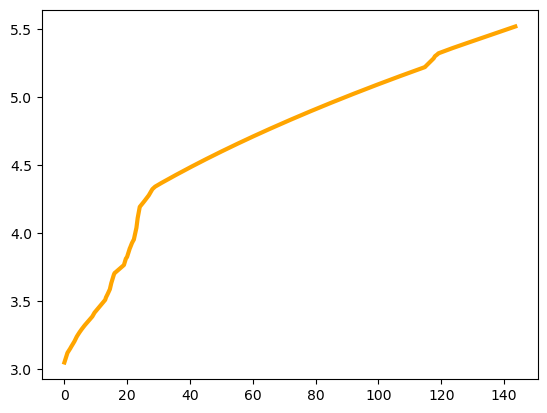

In [190]:
plt.plot(elike['Pressure_GPa'].iloc[ind_mant], elike['Density_g_cc'].iloc[ind_mant], color = 'orange', lw = 3)


In [191]:
def pth(T):
    return 0.00692*(T-300.0)

In [192]:
temp = 
plt.plot(pth(

39.444

In [195]:
pth(6000)/365.0

0.10806575342465755